## Combined Data Analysis & Machine Learning

This notebook combines all monthly trip CSV files, cleans the data, performs exploratory analysis, creates visualizations, and trains baseline machine-learning models.

**Models**
- XGBoost: hourly ride-demand prediction with lag features
- K-Means: station segmentation

## 1. Install dependencies
Run this cell once if the packages are not already installed.

In [19]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and configuration

In [20]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("outputs")
MODEL_DIR = OUTPUT_DIR / "models"
GRAPH_DIR = OUTPUT_DIR / "graphs"

for folder in (OUTPUT_DIR, MODEL_DIR, GRAPH_DIR):
  folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# Load the cleaned dataset
DATA_PATH = OUTPUT_DIR / "cleaned_divvy.csv"
df = pd.read_csv(DATA_PATH)

# Optional: verify shape
print(f"Dataset loaded successfully with {df.shape[0]:,} rows and {df.shape[1]} columns.")

Dataset loaded successfully with 10,396,299 rows and 26 columns.


## 4. Validate schema and inspect data

In [21]:
required_columns = [
    "ride_id", "rideable_type", "started_at", "ended_at",
    "start_station_name", "end_station_name",
    "start_lat", "start_lng", "end_lat", "end_lng",
    "member_casual"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

display(df.info())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
display(df["member_casual"].value_counts(dropna=False))
display(df["rideable_type"].value_counts(dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 10396299 entries, 0 to 10396298
Data columns (total 26 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             str    
 1   rideable_type       str    
 2   started_at          str    
 3   ended_at            str    
 4   start_station_name  str    
 5   start_station_id    str    
 6   end_station_name    str    
 7   end_station_id      str    
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       str    
 13  source_file         str    
 14  ride_duration_min   float64
 15  year                int64  
 16  month               int64  
 17  day                 int64  
 18  hour                int64  
 19  day_of_week         int64  
 20  day_name            str    
 21  month_name          str    
 22  date                str    
 23  is_weekend          int64  
 24  season              str    
 25  

None

,missing_values
end_station_name,2275764
end_station_id,2275764
start_station_id,2186897
start_station_name,2186897
end_lng,411
end_lat,411
ride_distance_km,411
started_at,0
rideable_type,0
ride_id,0


member_casual
member    6605605
casual    3790694
Name: count, dtype: int64

rideable_type
electric_bike    7093497
classic_bike     3302802
Name: count, dtype: int64

## 5. Clean data and engineer features
The cleaning rules remove duplicate ride IDs, invalid timestamps, non-positive trip durations, trips longer than 24 hours, and unrecognized rider categories. The 24-hour threshold is a configurable analytical rule, not a claim that longer records are impossible.

In [22]:
df = df.copy()

df = df.drop_duplicates(subset="ride_id")
df["started_at"] = pd.to_datetime(df["started_at"], errors="coerce")
df["ended_at"] = pd.to_datetime(df["ended_at"], errors="coerce")

df["ride_duration_min"] = (
    df["ended_at"] - df["started_at"]
).dt.total_seconds() / 60

df = df.dropna(subset=["started_at", "ended_at", "member_casual"])
df = df[
    df["ride_duration_min"].between(0.1, 1440, inclusive="both")
].copy()

df["member_casual"] = df["member_casual"].astype(str).str.lower().str.strip()
df = df[df["member_casual"].isin(["member", "casual"])].copy()

df["year"] = df["started_at"].dt.year
df["month"] = df["started_at"].dt.month
df["day_of_week"] = df["started_at"].dt.dayofweek
df["day_name"] = df["started_at"].dt.day_name()

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}
df["season"] = df["month"].map(season_map)

# Haversine distance between start and end coordinates (straight-line distance).
coord_cols = ["start_lat", "start_lng", "end_lat", "end_lng"]
for col in coord_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

valid_coords = df[coord_cols].notna().all(axis=1)
lat1 = np.radians(df.loc[valid_coords, "start_lat"])
lon1 = np.radians(df.loc[valid_coords, "start_lng"])
lat2 = np.radians(df.loc[valid_coords, "end_lat"])
lon2 = np.radians(df.loc[valid_coords, "end_lng"])

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
)
df["ride_distance_km"] = np.nan
df.loc[valid_coords, "ride_distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
)

print(f"Rows after cleaning: {len(df):,}")
print(f"Unique rides: {df['ride_id'].nunique():,}")
display(df.head())

Rows after cleaning: 10,396,299
Unique rides: 10,396,299


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,month,day,hour,day_of_week,day_name,month_name,date,is_weekend,season,ride_distance_km
0,FD0EB1D32AF0D47E,classic_bike,2026-01-31 09:13:09.018,2026-01-31 09:28:10.302,Central St & Girard Ave,CHI02042,Dodge Ave & Church St,CHI00741,42.064313,-87.686152,...,1,31,9,5,Saturday,January,2026-01-31,1,Winter,2.039755
1,FB27405C3F8C824F,classic_bike,2026-01-15 14:25:42.526,2026-01-15 14:33:18.854,Shore Dr & 55th St,CHI00394,Woodlawn Ave & 55th St,CHI00423,41.795212,-87.580715,...,1,15,14,3,Thursday,January,2026-01-15,0,Winter,1.306174
2,6FAFA1709403AA27,electric_bike,2026-01-06 12:55:33.572,2026-01-06 13:02:17.922,Hampden Ct & Diversey Pkwy,CHI02087,NaN,NaN,41.932470,-87.642420,...,1,6,12,1,Tuesday,January,2026-01-06,0,Winter,0.860893
3,1F34C1FAD9FEC2D8,electric_bike,2026-01-26 16:22:25.011,2026-01-26 16:53:15.197,Carpenter St & Huron St,CHI00286,NaN,NaN,41.894532,-87.653412,...,1,26,16,0,Monday,January,2026-01-26,0,Winter,7.305991
4,8E3E3072D8D3D918,electric_bike,2026-01-10 18:13:30.139,2026-01-10 19:31:56.971,Clinton St & Madison St,CHI00233,NaN,NaN,41.881660,-87.641150,...,1,10,18,5,Saturday,January,2026-01-10,1,Winter,1.308424


In [23]:
df['trip_type'] = np.where(
    df['start_station_name'] == df['end_station_name'],
    'Round trip',
    'One-way'
)

In [24]:
df['trip_type'] = np.select(
    [
        df['start_station_name'].isna() | df['end_station_name'].isna(),
        df['start_station_name'] == df['end_station_name']
    ],
    ['Unknown', 'Round trip'],
    default='One-way'
)

In [25]:
print(df['trip_type'].value_counts())
print(df['trip_type'].value_counts(normalize=True).mul(100).round(1))

trip_type
One-way       6579073
Unknown       3468069
Round trip     349157
Name: count, dtype: int64
trip_type
One-way       63.3
Unknown       33.4
Round trip     3.4
Name: proportion, dtype: float64


In [26]:
df.sample(5, random_state=RANDOM_STATE)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,day,hour,day_of_week,day_name,month_name,date,is_weekend,season,ride_distance_km,trip_type
823504,0839AE96A61AC4E9,electric_bike,2025-04-30 08:14:23.252,2025-04-30 08:46:47.348,Clinton St & Washington Blvd,WL-012,NaN,NaN,41.883000,-87.641273,...,30,8,2,Wednesday,April,2025-04-30,0,Spring,1.925334,Unknown
8105681,2D24BA191F9ECF10,electric_bike,2026-07-19 11:27:06.461,2026-07-19 11:37:28.026,NaN,NaN,Morgan St & Lake St,CHI00878,41.890000,-87.640000,...,19,11,6,Sunday,July,2026-07-19,1,Summer,1.134108,Unknown
33793,405704FF7AF3E7AB,classic_bike,2026-01-08 09:38:02.235,2026-01-08 09:40:58.798,LaSalle Dr & Huron St,CHI00640,Wells St & Hubbard St,CHI00332,41.894877,-87.632326,...,8,9,3,Thursday,January,2026-01-08,0,Winter,0.575603,One-way
1286034,A8BE5C92CB3F28D2,electric_bike,2025-05-14 18:14:36.900,2025-05-14 18:21:52.700,NaN,NaN,NaN,NaN,42.040000,-87.690000,...,14,18,2,Wednesday,May,2025-05-14,0,Spring,2.372233,Unknown
4682528,70483082DF95AA20,electric_bike,2025-10-23 08:26:05.052,2025-10-23 08:43:11.633,NaN,NaN,Canal St & Adams St,CHI01743,41.900000,-87.670000,...,23,8,3,Thursday,October,2025-10-23,0,Autumn,3.395205,Unknown


In [27]:
round_trips = df[df['trip_type'] == 'Round trip']
one_way = df[df['trip_type'] == 'One-way']

In [28]:
# Which rider type does more round trips
print(pd.crosstab(df['member_casual'], df['trip_type'], normalize='index').mul(100).round(1))

# Average duration
print(df.groupby('trip_type')['ride_duration_min'].mean())

trip_type      One-way  Round trip  Unknown
member_casual                              
casual            59.9         5.8     34.3
member            65.2         2.0     32.8
trip_type
One-way       14.997067
Round trip    27.181999
Unknown       12.100443
Name: ride_duration_min, dtype: float64


In [29]:
df.sample(5, random_state=RANDOM_STATE)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,day,hour,day_of_week,day_name,month_name,date,is_weekend,season,ride_distance_km,trip_type
823504,0839AE96A61AC4E9,electric_bike,2025-04-30 08:14:23.252,2025-04-30 08:46:47.348,Clinton St & Washington Blvd,WL-012,NaN,NaN,41.883000,-87.641273,...,30,8,2,Wednesday,April,2025-04-30,0,Spring,1.925334,Unknown
8105681,2D24BA191F9ECF10,electric_bike,2026-07-19 11:27:06.461,2026-07-19 11:37:28.026,NaN,NaN,Morgan St & Lake St,CHI00878,41.890000,-87.640000,...,19,11,6,Sunday,July,2026-07-19,1,Summer,1.134108,Unknown
33793,405704FF7AF3E7AB,classic_bike,2026-01-08 09:38:02.235,2026-01-08 09:40:58.798,LaSalle Dr & Huron St,CHI00640,Wells St & Hubbard St,CHI00332,41.894877,-87.632326,...,8,9,3,Thursday,January,2026-01-08,0,Winter,0.575603,One-way
1286034,A8BE5C92CB3F28D2,electric_bike,2025-05-14 18:14:36.900,2025-05-14 18:21:52.700,NaN,NaN,NaN,NaN,42.040000,-87.690000,...,14,18,2,Wednesday,May,2025-05-14,0,Spring,2.372233,Unknown
4682528,70483082DF95AA20,electric_bike,2025-10-23 08:26:05.052,2025-10-23 08:43:11.633,NaN,NaN,Canal St & Adams St,CHI01743,41.900000,-87.670000,...,23,8,3,Thursday,October,2025-10-23,0,Autumn,3.395205,Unknown


## 6. Descriptive statistics and key summaries

In [30]:
summary = pd.DataFrame({
    "metric": [
        "Total cleaned rides",
        "Unique ride IDs",
        "Average ride duration (min)",
        "Median ride duration (min)",
        "Average straight-line distance (km)",
        "Member share (%)",
        "Casual share (%)"
    ],
    "value": [
        len(df),
        df["ride_id"].nunique(),
        df["ride_duration_min"].mean(),
        df["ride_duration_min"].median(),
        df["ride_distance_km"].mean(),
        (df["member_casual"].eq("member").mean() * 100),
        (df["member_casual"].eq("casual").mean() * 100)
    ]
})
display(summary)
display(df.groupby("member_casual")["ride_duration_min"].agg(
    ["count", "mean", "median", "std"]
))
display(df.groupby("rideable_type").agg(
    rides=("ride_id", "count"),
    avg_duration_min=("ride_duration_min", "mean")
).sort_values("rides", ascending=False))

,metric,value
0,Total cleaned rides,1.039630e+07
1,Unique ride IDs,1.039630e+07
2,Average ride duration (min),1.444002e+01
3,Median ride duration (min),9.484650e+00
4,Average straight-line distance (km),2.224315e+00
5,Member share (%),6.353804e+01
6,Casual share (%),3.646196e+01


,count,mean,median,std
member_casual,,,,
casual,3790694,18.613667,11.271917,36.717788
member,6605605,12.044928,8.669100,19.916814


,rides,avg_duration_min
rideable_type,,
electric_bike,7093497,12.337469
classic_bike,3302802,18.955708


## 7. Monthly demand analysis

In [31]:
monthly_rides = (
    df.groupby(df["started_at"].dt.to_period("M"))
      .size()
      .rename("total_rides")
      .reset_index()
)
monthly_rides["month"] = monthly_rides["started_at"].astype(str)
monthly_rides = monthly_rides.drop(columns="started_at")
display(monthly_rides)
monthly_rides.to_csv(OUTPUT_DIR / "monthly_rides.csv", index=False)

,total_rides,month
0,15,2025-01
1,151449,2025-02
2,296848,2025-03
3,369893,2025-04
4,500365,2025-05
5,675308,2025-06
6,759706,2025-07
7,786908,2025-08
8,711855,2025-09
9,643666,2025-10


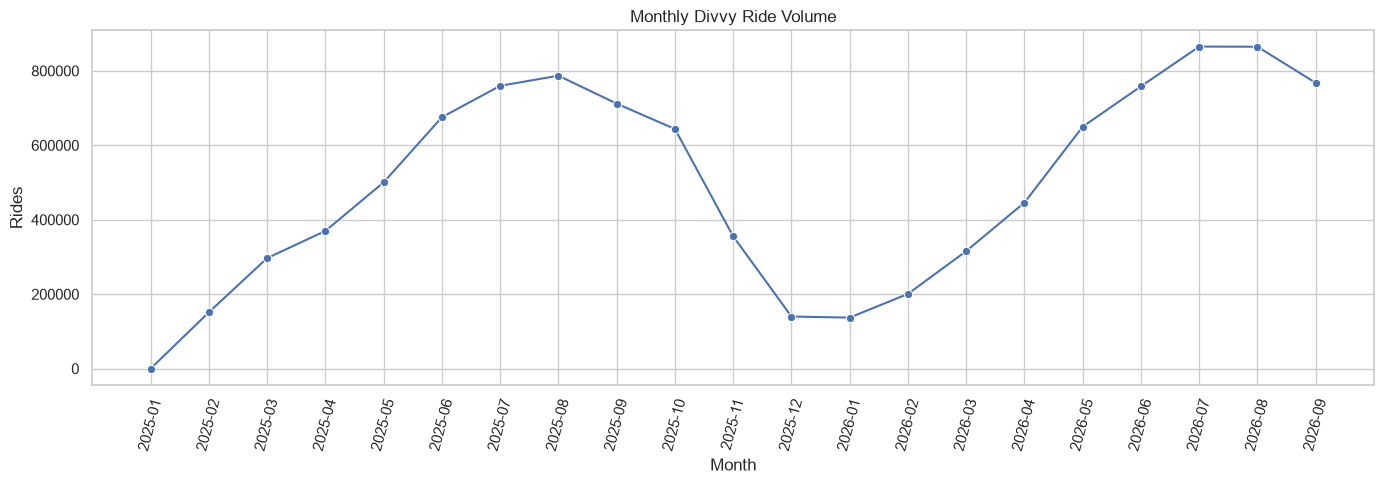

In [32]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=monthly_rides, x="month", y="total_rides", marker="o", ax=ax)
ax.set(title="Monthly Divvy Ride Volume", xlabel="Month", ylabel="Rides")
ax.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "monthly_trends.png", dpi=200)
plt.show()

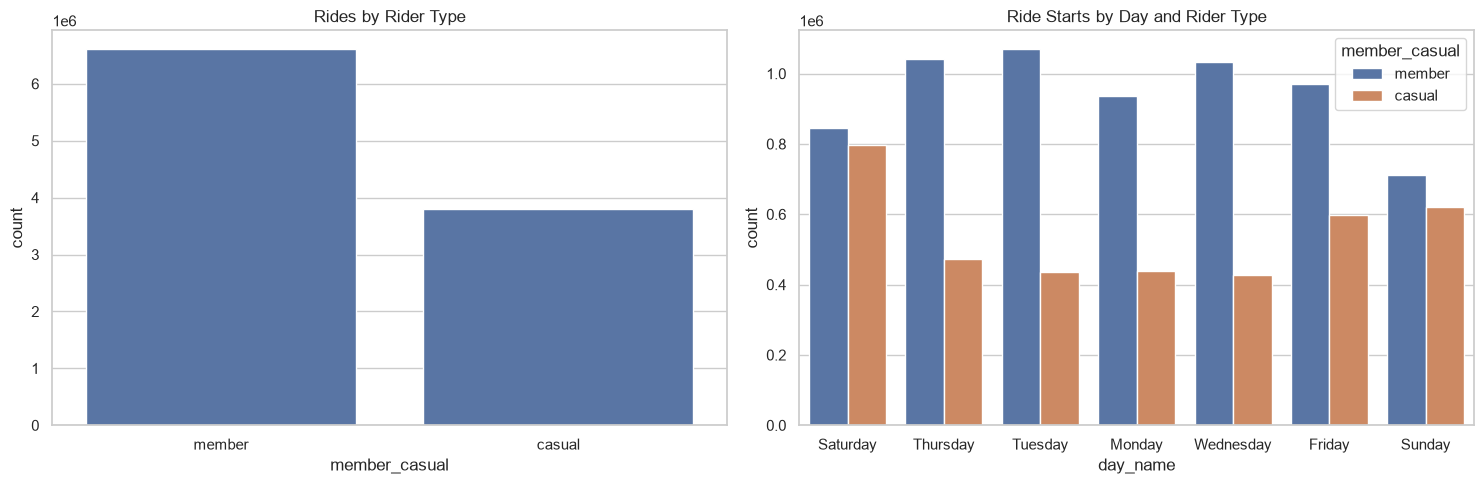

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="member_casual", ax=axes[0])
axes[0].set_title("Rides by Rider Type")
sns.countplot(data=df, x="day_name", hue="member_casual", ax=axes[1])
axes[1].set_title("Ride Starts by Day and Rider Type")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "rider_and_daily_patterns.png", dpi=200)
plt.show()

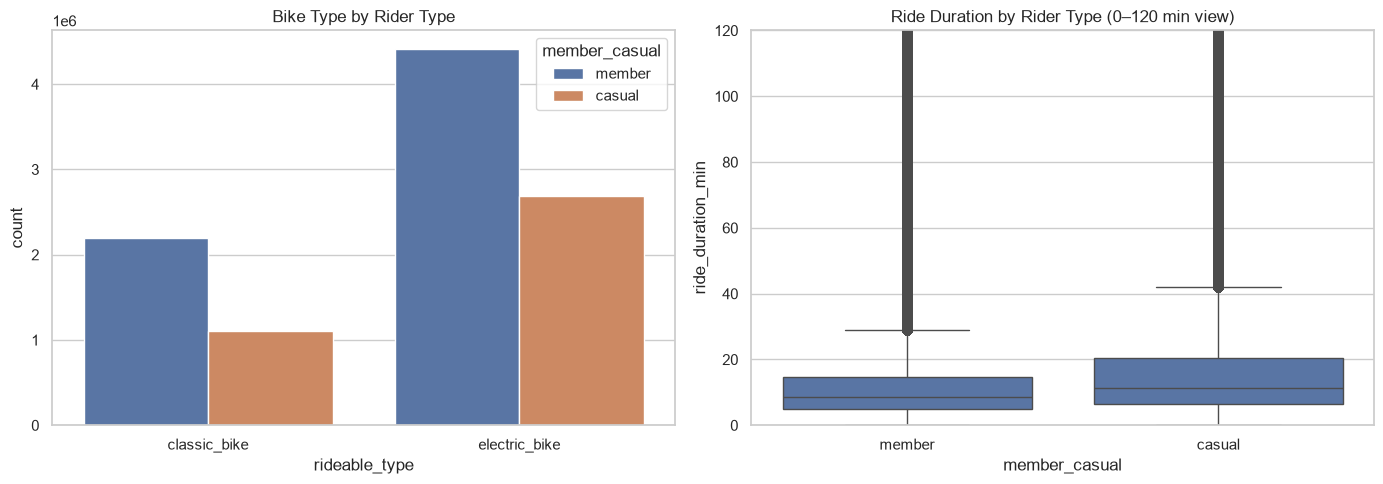

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="rideable_type", hue="member_casual", ax=axes[0])
axes[0].set_title("Bike Type by Rider Type")
sns.boxplot(data=df, x="member_casual", y="ride_duration_min", ax=axes[1])
axes[1].set_ylim(0, 120)
axes[1].set_title("Ride Duration by Rider Type (0–120 min view)")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "bike_and_duration.png", dpi=200)
plt.show()

## 8. Station and route analysis

In [35]:
top_start_stations = (
    df["start_station_name"].value_counts().head(15)
    .rename_axis("station").reset_index(name="rides")
)
top_end_stations = (
    df["end_station_name"].value_counts().head(15)
    .rename_axis("station").reset_index(name="rides")
)
display(top_start_stations)
display(top_end_stations)
top_start_stations.to_csv(OUTPUT_DIR / "top_start_stations.csv", index=False)

route_counts = (
    df.dropna(subset=["start_station_name", "end_station_name"])
      .groupby(["start_station_name", "end_station_name"])
      .size().sort_values(ascending=False)
      .head(20).rename("rides").reset_index()
)
display(route_counts)
route_counts.to_csv(OUTPUT_DIR / "top_routes.csv", index=False)

,station,rides
0,Navy Pier,92428
1,DuSable Lake Shore Dr & Monroe St,70148
2,Michigan Ave & Oak St,64446
3,DuSable Lake Shore Dr & North Blvd,61367
4,Canal St & Madison St,50692
5,Theater on the Lake,50472
6,State St & Chicago Ave,49818
7,Wells St & Concord Ln,49583
8,Millennium Park,48322
9,Wells St & Elm St,48047


,station,rides
0,Navy Pier,91530
1,DuSable Lake Shore Dr & Monroe St,67052
2,Michigan Ave & Oak St,63878
3,DuSable Lake Shore Dr & North Blvd,63380
4,Theater on the Lake,52060
5,Canal St & Madison St,50550
6,State St & Chicago Ave,49863
7,Wells St & Concord Ln,49621
8,Millennium Park,48178
9,Wells St & Elm St,47345


,start_station_name,end_station_name,rides
0,Navy Pier,Navy Pier,15180
1,DuSable Lake Shore Dr & Monroe St,DuSable Lake Shore Dr & Monroe St,11697
2,Michigan Ave & Oak St,Michigan Ave & Oak St,7981
3,DuSable Lake Shore Dr & Monroe St,Navy Pier,6720
4,Ellis Ave & 60th St,Ellis Ave & 55th St,6717
5,Ellis Ave & 55th St,Ellis Ave & 60th St,6384
6,Ellis Ave & 60th St,University Ave & 57th St,5338
7,University Ave & 57th St,Ellis Ave & 60th St,5094
8,Millennium Park,Millennium Park,5030
9,Dusable Harbor,Dusable Harbor,4891


In [36]:
df.sample(5, random_state=RANDOM_STATE)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,day,hour,day_of_week,day_name,month_name,date,is_weekend,season,ride_distance_km,trip_type
823504,0839AE96A61AC4E9,electric_bike,2025-04-30 08:14:23.252,2025-04-30 08:46:47.348,Clinton St & Washington Blvd,WL-012,NaN,NaN,41.883000,-87.641273,...,30,8,2,Wednesday,April,2025-04-30,0,Spring,1.925334,Unknown
8105681,2D24BA191F9ECF10,electric_bike,2026-07-19 11:27:06.461,2026-07-19 11:37:28.026,NaN,NaN,Morgan St & Lake St,CHI00878,41.890000,-87.640000,...,19,11,6,Sunday,July,2026-07-19,1,Summer,1.134108,Unknown
33793,405704FF7AF3E7AB,classic_bike,2026-01-08 09:38:02.235,2026-01-08 09:40:58.798,LaSalle Dr & Huron St,CHI00640,Wells St & Hubbard St,CHI00332,41.894877,-87.632326,...,8,9,3,Thursday,January,2026-01-08,0,Winter,0.575603,One-way
1286034,A8BE5C92CB3F28D2,electric_bike,2025-05-14 18:14:36.900,2025-05-14 18:21:52.700,NaN,NaN,NaN,NaN,42.040000,-87.690000,...,14,18,2,Wednesday,May,2025-05-14,0,Spring,2.372233,Unknown
4682528,70483082DF95AA20,electric_bike,2025-10-23 08:26:05.052,2025-10-23 08:43:11.633,NaN,NaN,Canal St & Adams St,CHI01743,41.900000,-87.670000,...,23,8,3,Thursday,October,2025-10-23,0,Autumn,3.395205,Unknown


## 10. XGBoost — hourly demand prediction
Demand is aggregated into a continuous hourly time series. Missing hours are filled with zero rides. Lag and rolling features use only prior hours. The test set is the final 20% of time, preserving chronology.

In [37]:
hourly = (
    df.set_index("started_at")
      .resample("h")
      .size()
      .rename("ride_count")
      .to_frame()
)
hourly.index.name = "timestamp"

# Add calendar predictors
hourly["hour"] = hourly.index.hour
hourly["day_of_week"] = hourly.index.dayofweek
hourly["month"] = hourly.index.month
hourly["day_of_year"] = hourly.index.dayofyear
hourly["is_weekend"] = (hourly["day_of_week"] >= 5).astype(int)

# Cyclical encodings
hourly["hour_sin"] = np.sin(2 * np.pi * hourly["hour"] / 24)
hourly["hour_cos"] = np.cos(2 * np.pi * hourly["hour"] / 24)
hourly["dow_sin"] = np.sin(2 * np.pi * hourly["day_of_week"] / 7)
hourly["dow_cos"] = np.cos(2 * np.pi * hourly["day_of_week"] / 7)

for lag in [1, 2, 24, 48, 168]:
    hourly[f"lag_{lag}"] = hourly["ride_count"].shift(lag)

hourly["rolling_mean_24"] = hourly["ride_count"].shift(1).rolling(24).mean()
hourly["rolling_mean_168"] = hourly["ride_count"].shift(1).rolling(168).mean()

feature_cols = [
    "hour", "day_of_week", "month", "day_of_year", "is_weekend",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "lag_1", "lag_2", "lag_24", "lag_48", "lag_168",
    "rolling_mean_24", "rolling_mean_168"
]

model_data = hourly.dropna(subset=feature_cols + ["ride_count"]).copy()
X_demand = model_data[feature_cols]
y_demand = model_data["ride_count"]

split_idx = int(len(model_data) * 0.8)
if split_idx <= 0 or split_idx >= len(model_data):
    raise ValueError("Not enough hourly observations for a chronological train/test split.")

X_train_d, X_test_d = X_demand.iloc[:split_idx], X_demand.iloc[split_idx:]
y_train_d, y_test_d = y_demand.iloc[:split_idx], y_demand.iloc[split_idx:]

xgb_model = XGBRegressor(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=RANDOM_STATE
)
xgb_model.fit(X_train_d, y_train_d)
xgb_pred = np.maximum(0, xgb_model.predict(X_test_d))

xgb_metrics = {
    "MAE_rides_per_hour": mean_absolute_error(y_test_d, xgb_pred),
    "RMSE_rides_per_hour": mean_squared_error(y_test_d, xgb_pred) ** 0.5,
    "R2": r2_score(y_test_d, xgb_pred)
}
display(pd.DataFrame([xgb_metrics]))
joblib.dump(xgb_model, MODEL_DIR / "xgboost_hourly_demand.joblib")

,MAE_rides_per_hour,RMSE_rides_per_hour,R2
0,141.644852,228.696237,0.92882


['outputs\\models\\xgboost_hourly_demand.joblib']

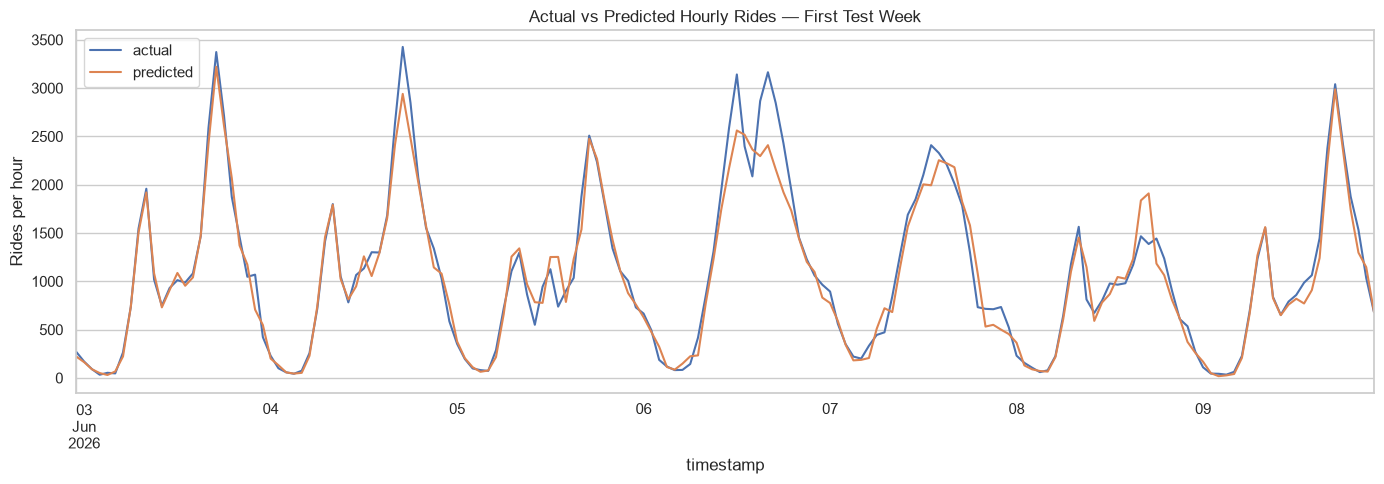

In [38]:
comparison = pd.DataFrame({
    "actual": y_test_d,
    "predicted": xgb_pred
}, index=y_test_d.index)

fig, ax = plt.subplots(figsize=(14, 5))
comparison.iloc[:min(24*7, len(comparison))].plot(ax=ax)
ax.set_title("Actual vs Predicted Hourly Rides — First Test Week")
ax.set_ylabel("Rides per hour")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "demand_actual_vs_predicted.png", dpi=200)
plt.show()

## 11. K-Means — station segmentation
Stations are clustered using geographic coordinates, ride volume and average ride duration. Standardization is applied because these variables have different units.

,stations,mean_rides,mean_duration
cluster,,,
0,266,22235.661654,14.692069
1,1089,1529.436180,15.364915
2,802,784.488778,16.665804


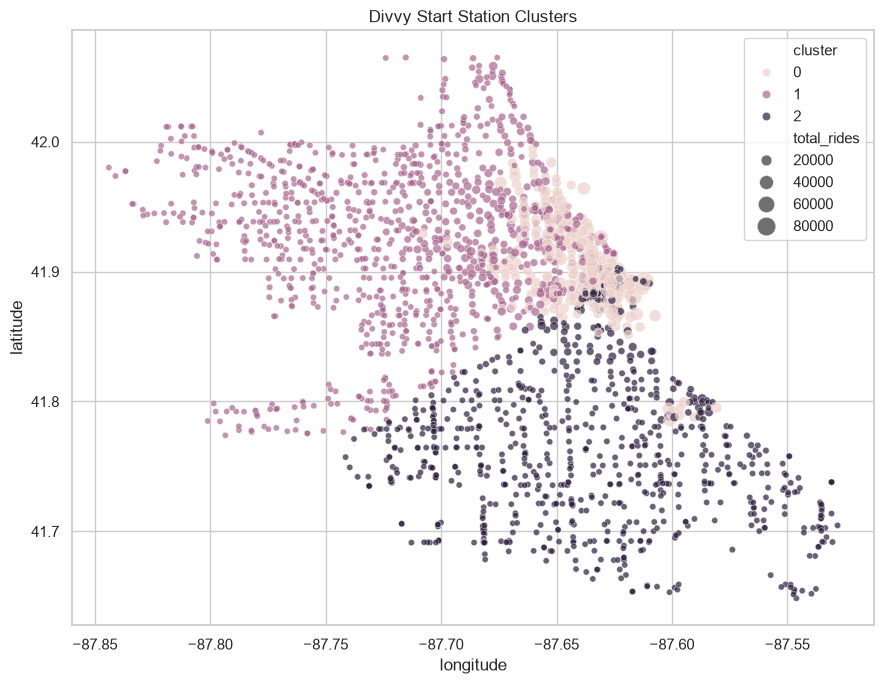

In [39]:
station_source = df.dropna(
    subset=["start_station_name", "start_lat", "start_lng"]
).copy()

station_stats = (
    station_source.groupby("start_station_name")
    .agg(
        latitude=("start_lat", "mean"),
        longitude=("start_lng", "mean"),
        total_rides=("ride_id", "count"),
        avg_duration_min=("ride_duration_min", "mean")
    )
    .reset_index()
)

cluster_features = ["latitude", "longitude", "total_rides", "avg_duration_min"]
station_stats = station_stats.dropna(subset=cluster_features)

if len(station_stats) >= 3:
    scaler = StandardScaler()
    scaled = scaler.fit_transform(station_stats[cluster_features])

    kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
    station_stats["cluster"] = kmeans.fit_predict(scaled)

    display(station_stats.groupby("cluster").agg(
        stations=("start_station_name", "count"),
        mean_rides=("total_rides", "mean"),
        mean_duration=("avg_duration_min", "mean")
    ))

    joblib.dump(scaler, MODEL_DIR / "station_scaler.joblib")
    joblib.dump(kmeans, MODEL_DIR / "kmeans_stations.joblib")
    station_stats.to_csv(OUTPUT_DIR / "station_clusters.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.scatterplot(
        data=station_stats, x="longitude", y="latitude",
        hue="cluster", size="total_rides", sizes=(20, 200),
        alpha=0.7, ax=ax
    )
    ax.set_title("Divvy Start Station Clusters")
    plt.tight_layout()
    plt.savefig(GRAPH_DIR / "station_clusters.png", dpi=200)
    plt.show()
else:
    print("Not enough valid stations for 3-cluster K-Means.")

## 12. Export final metrics and business summaries

In [41]:
final_metrics = {
    "csv_files_loaded": len(csv_files),
    "cleaned_ride_records": len(df),
    "unique_rides": df["ride_id"].nunique(),
    "average_duration_minutes": df["ride_duration_min"].mean(),
    "median_duration_minutes": df["ride_duration_min"].median(),
    "average_straight_line_distance_km": df["ride_distance_km"].mean(),
    "member_percentage": df["member_casual"].eq("member").mean() * 100,
    "casual_percentage": df["member_casual"].eq("casual").mean() * 100,
    "xgboost_MAE_rides_per_hour": xgb_metrics["MAE_rides_per_hour"],
    "xgboost_RMSE_rides_per_hour": xgb_metrics["RMSE_rides_per_hour"],
    "xgboost_R2": xgb_metrics["R2"]
}

pd.DataFrame([final_metrics]).to_csv(OUTPUT_DIR / "final_report.csv", index=False)

rider_summary = df.groupby("member_casual").agg(
    total_rides=("ride_id", "count"),
    avg_duration_min=("ride_duration_min", "mean"),
    median_duration_min=("ride_duration_min", "median"),
    avg_distance_km=("ride_distance_km", "mean")
)
rider_summary.to_csv(OUTPUT_DIR / "rider_analysis.csv")

bike_summary = df.groupby("rideable_type").agg(
    total_rides=("ride_id", "count"),
    avg_duration_min=("ride_duration_min", "mean")
)
bike_summary.to_csv(OUTPUT_DIR / "bike_analysis.csv")

display(pd.DataFrame([final_metrics]).T.rename(columns={0: "value"}))
print(f"All outputs saved under: {OUTPUT_DIR.resolve()}")

,value
csv_files_loaded,0.000000e+00
cleaned_ride_records,1.039630e+07
unique_rides,1.039630e+07
average_duration_minutes,1.444002e+01
median_duration_minutes,9.484650e+00
average_straight_line_distance_km,2.224315e+00
member_percentage,6.353804e+01
casual_percentage,3.646196e+01
xgboost_MAE_rides_per_hour,1.416449e+02
xgboost_RMSE_rides_per_hour,2.286962e+02


All outputs saved under: D:\Machine learning\outputs


## 13. Interpretation checklist

Use the generated tables and charts to answer:

1. Which months have the highest and lowest ride volume?
2. How do annual and seasonal patterns compare?
3. Do members and casual riders use bikes at different times or on different days?
4. Which bike type is most frequently used?
5. Which stations and routes receive the most traffic?
6. Which stations fall into high-, medium-, and low-activity clusters?
7. How well does the hourly demand model perform on the final chronological test period?

**Important limitations**
- Straight-line coordinate distance is not actual road or cycling distance.
- Ride duration can be affected by outliers, stops, and data errors.
- The duration model includes destination coordinates, so it is not a pre-trip estimate.
- The XGBoost model is a baseline. Its lag features are appropriate for one-step-ahead evaluation, but multi-hour forecasting requires recursive or direct multi-step forecasting.
- The 2026 data shown in the supplied file list ends in October, so comparisons should account for incomplete years.